In [1]:

import gc
import sys
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from scipy.stats import rankdata
from torch.utils.data import DataLoader
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0,str(ROOT_DIR))
from model import SparseLandauScoreField,SparseLandauScoreFieldWithoutForce,SparseLandauScoreFieldWithoutFreeEnergy,SparseLandauScoreFieldWithoutResidual,SparseLandauScoreFieldWithoutEvidence,SparseLandauScoreFieldTemperatureOne
from others import create_baseline
from rating_dataset import RatingDataset
TEST_DIR=ROOT_DIR/'data'/'test_face_data'
TRAIN_DIR=ROOT_DIR/'data'/'face_data'
WEIGHTS_DIR=ROOT_DIR/'weights'
ABLATION_LOG_FILE=ROOT_DIR/'outputs'/'ablation'/'seed_best_metrics.csv'
MAIN_TABLE_FILE=ROOT_DIR/'outputs'/'tables'/'main_comparison.csv'
TABLE_DIR=ROOT_DIR/'outputs'/'tables'
TABLE_FILE=TABLE_DIR/'ablation_comparison.csv'
VARIANTS=['full_sse','without_force','without_free_energy','without_residual','without_evidence','temperature_one']
VARIANT_CLASSES={'without_force':SparseLandauScoreFieldWithoutForce,'without_free_energy':SparseLandauScoreFieldWithoutFreeEnergy,'without_residual':SparseLandauScoreFieldWithoutResidual,'without_evidence':SparseLandauScoreFieldWithoutEvidence,'temperature_one':SparseLandauScoreFieldTemperatureOne}
ABLATION_CONFIGS={'without_force':{'use_force_field':False,'use_free_energy':True,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.10},'without_free_energy':{'use_force_field':True,'use_free_energy':False,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.10},'without_residual':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':False,'use_evidence':True,'output_temperature':1.10},'without_evidence':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':True,'use_evidence':False,'output_temperature':1.10},'temperature_one':{'use_force_field':True,'use_free_energy':True,'use_direct_residual':True,'use_evidence':True,'output_temperature':1.00}}
SEEDS=[42,123,2026,3407,777]
METRICS=['emd','mae','nll','spearman']
IMAGE_SIZE=336
IMAGE_BATCH_SIZE=4
HEAD_BATCH_SIZE=128
NUM_WORKERS=0
BOOTSTRAP_REPEATS=2000
PERMUTATION_REPEATS=3000
CONFIDENCE_LEVEL=0.95
ALPHA=0.05
RNG_SEED=20261102
FULL_MATCH_TOL=0.0005
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
USE_AMP=DEVICE.type=='cuda'
if len(SEEDS)<2 or len(SEEDS)!=len(set(SEEDS)):
    raise ValueError('训练随机种子必须至少两个且不能重复')
if not 0.0<CONFIDENCE_LEVEL<1.0 or not 0.0<ALPHA<1.0:
    raise ValueError('置信度和显著性阈值必须在(0,1)之间')
for required_path in [TEST_DIR,WEIGHTS_DIR]:
    if not required_path.is_dir():
        raise FileNotFoundError(f'目录不存在: {required_path}')
for required_file in [ABLATION_LOG_FILE,MAIN_TABLE_FILE]:
    if not required_file.is_file():
        raise FileNotFoundError(f'记录文件不存在: {required_file}')
checkpoint_paths={(variant,seed):WEIGHTS_DIR/(f'ours_{seed}.pt' if variant=='full_sse' else f'{variant}_{seed}.pt') for variant in VARIANTS for seed in SEEDS}
missing_checkpoints=[str(path) for path in checkpoint_paths.values() if not path.is_file()]
if missing_checkpoints:
    raise FileNotFoundError('缺少消融测试权重:\n'+'\n'.join(missing_checkpoints))
ablation_log=pd.read_csv(ABLATION_LOG_FILE)
if not {'variant','seed','checkpoint','best_epoch'}.issubset(ablation_log.columns):
    raise RuntimeError('seed_best_metrics.csv缺少必要列')
ablation_log['variant']=ablation_log['variant'].astype(str)
ablation_log['seed']=pd.to_numeric(ablation_log['seed'],errors='raise').astype(int)
for variant in VARIANTS:
    for seed in SEEDS:
        records=ablation_log.loc[(ablation_log['variant']==variant)&(ablation_log['seed']==seed)]
        if len(records)!=1 or Path(str(records.iloc[0]['checkpoint'])).name!=checkpoint_paths[(variant,seed)].name:
            raise RuntimeError(f'消融训练记录与权重不一致: {variant}, seed={seed}')
main_table=pd.read_csv(MAIN_TABLE_FILE)
main_ours=main_table.loc[main_table['model']=='ours']
if len(main_ours)!=1:
    raise RuntimeError('主对比表中必须有且仅有一条ours记录')
main_ours=main_ours.iloc[0]
if str(main_ours['train_seeds'])!=','.join(str(seed) for seed in SEEDS):
    raise RuntimeError('主对比表使用的训练种子与本次消融不一致')
test_dataset=RatingDataset(str(TEST_DIR),mask_dir=None,augment=False,repeat=1,image_size=IMAGE_SIZE,soft_target=False)
test_loader=DataLoader(test_dataset,batch_size=IMAGE_BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS,pin_memory=USE_AMP)
TEST_NAMES=[path.name for path in test_dataset.image_paths]
TEST_COUNTS=np.asarray([len(test_dataset._read_scores(path.with_suffix('.txt'))) for path in test_dataset.image_paths],dtype=np.int32)
if len(TEST_NAMES)!=int(main_ours['test_photos']) or int((TEST_COUNTS==1).sum())!=int(main_ours['single_rating_photos']):
    raise RuntimeError('测试集数量或单评分照片数量与主对比实验不一致，禁止混用数据划分')
if TRAIN_DIR.is_dir():
    train_names={path.name.casefold() for path in TRAIN_DIR.iterdir() if path.suffix.lower() in {'.jpg','.jpeg','.png'}}
    duplicate_names=sorted({name.casefold() for name in TEST_NAMES}&train_names)
    if duplicate_names:
        raise RuntimeError(f'测试集与训练/验证集存在同名照片: {duplicate_names[:10]}')
print(f'设备: {DEVICE} | 测试图片: {len(TEST_NAMES)} | 消融变体: {len(VARIANTS)} | 独立种子: {len(SEEDS)} | 权重: {len(checkpoint_paths)}')
print('本Notebook仅执行测试评估，不重新训练，不修改任何权重')


设备: cuda | 测试图片: 1480 | 消融变体: 6 | 独立种子: 5 | 权重: 30
本Notebook仅执行测试评估，不重新训练，不修改任何权重


In [2]:

class FrozenEncoderTokenAdapter(torch.nn.Module):
    def __init__(self,encoder,input_size,mean,std):
        super().__init__()
        self.encoder=encoder
        self.embed_dim=int(encoder.num_features)
        self.global_only=True
        self.input_size=int(input_size)
        self.register_buffer('mean',mean.detach().clone())
        self.register_buffer('std',std.detach().clone())
    def train(self,mode=True):
        super().train(mode)
        self.encoder.eval()
        return self
def build_sse(variant,adapter):
    kwargs={'pretrained':False,'backbone':adapter,'dropout':0.10,'train_last_stage':False,'width':24,'prior_mix':0.0,'use_entropy':False,'use_high_resolution':False,'scales':(224,),'grid_side':16,'use_evidence_head':True,'evidence_base':0.1,'use_global_token':True}
    if variant=='full_sse':
        return SparseLandauScoreField(**kwargs)
    return VARIANT_CLASSES[variant](**kwargs,**ABLATION_CONFIGS[variant])
def load_state(path):
    state=torch.load(path,map_location='cpu',weights_only=True)
    if not isinstance(state,dict) or not all(isinstance(value,torch.Tensor) for value in state.values()):
        raise RuntimeError(f'权重不是直接保存的state_dict: {path}')
    return state
def verify_frozen_inputs(reference,state,variant,seed):
    protected=[name for name in reference if name.startswith('backbone.') or name in ('mean','std')]
    mismatched=[name for name in protected if name not in state or not torch.equal(reference[name],state[name])]
    if mismatched:
        raise RuntimeError(f'{variant}_{seed}的冻结编码器或图像标准化参数不一致: {mismatched[:5]}')
@torch.inference_mode()
def extract_test_features(model):
    model.eval()
    features=[]
    labels=[]
    for images,targets in test_loader:
        images=images.to(DEVICE,non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
            encoded=model.encode_features(images)
        features.append(encoded.float().cpu())
        labels.append(targets.float().cpu())
    return torch.cat(features,dim=0),torch.cat(labels,dim=0).numpy().astype(np.float64)
@torch.inference_mode()
def predict_features(model,features):
    model.eval()
    batches=[]
    for start in range(0,len(features),HEAD_BATCH_SIZE):
        batch=features[start:start+HEAD_BATCH_SIZE].to(DEVICE,non_blocking=True)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=USE_AMP):
            log_probs,_=model.forward_from_features(batch)
        batches.append(torch.softmax(log_probs.float(),dim=1).cpu().numpy().astype(np.float64))
    predicted=np.concatenate(batches,axis=0)
    if not np.isfinite(predicted).all() or (predicted<0).any() or not np.allclose(predicted.sum(axis=1),1.0,atol=1e-5):
        raise RuntimeError('预测概率不是合法的十维分布')
    return predicted
encoder_model=create_baseline('TIPSV2',pretrained=False,freeze_backbone=True,dropout=0.0)
tip_adapter=FrozenEncoderTokenAdapter(encoder_model.backbone,encoder_model.input_size,encoder_model.mean,encoder_model.std)
del encoder_model
full_model=build_sse('full_sse',tip_adapter)
reference_state=load_state(checkpoint_paths[('full_sse',SEEDS[0])])
full_model.load_state_dict(reference_state,strict=True)
full_model=full_model.to(DEVICE).eval()
feature_values,test_targets=extract_test_features(full_model)
if test_targets.shape!=(len(TEST_NAMES),10) or not np.isfinite(test_targets).all() or not np.allclose(test_targets.sum(axis=1),1.0,atol=1e-6):
    raise RuntimeError('测试标签不是合法的十维概率分布')
all_predictions={}
full_predictions=[]
for seed in SEEDS:
    state=reference_state if seed==SEEDS[0] else load_state(checkpoint_paths[('full_sse',seed)])
    verify_frozen_inputs(reference_state,state,'full_sse',seed)
    full_model.load_state_dict(state,strict=True)
    full_predictions.append(predict_features(full_model,feature_values))
    print(f'已测试 full_sse_{seed}',flush=True)
    if seed!=SEEDS[0]:
        del state
all_predictions['full_sse']=np.stack(full_predictions,axis=0)
del full_model,full_predictions
for variant in VARIANTS[1:]:
    model=build_sse(variant,tip_adapter).to(DEVICE).eval()
    expected_keys=set(model.state_dict().keys())
    backbone_keys={key for key in expected_keys if key.startswith('backbone.')}
    variant_predictions=[]
    for seed in SEEDS:
        state=load_state(checkpoint_paths[(variant,seed)])
        if set(state.keys())!=expected_keys-backbone_keys:
            raise RuntimeError(f'{variant}_{seed}的紧凑权重字段与当前模型不一致')
        result=model.load_state_dict(state,strict=False)
        if set(result.missing_keys)!=backbone_keys or result.unexpected_keys:
            raise RuntimeError(f'{variant}_{seed}紧凑权重加载不完整: {result}')
        variant_predictions.append(predict_features(model,feature_values))
        print(f'已测试 {variant}_{seed}',flush=True)
        del state
    all_predictions[variant]=np.stack(variant_predictions,axis=0)
    del model,variant_predictions
    gc.collect()
    if USE_AMP:
        torch.cuda.empty_cache()
del reference_state,feature_values,tip_adapter
print('30份权重全部完成推理，消融组共用同一份冻结TIPSV2测试特征')


已测试 full_sse_42
已测试 full_sse_123
已测试 full_sse_2026
已测试 full_sse_3407
已测试 full_sse_777
已测试 without_force_42
已测试 without_force_123
已测试 without_force_2026
已测试 without_force_3407
已测试 without_force_777
已测试 without_free_energy_42
已测试 without_free_energy_123
已测试 without_free_energy_2026
已测试 without_free_energy_3407
已测试 without_free_energy_777
已测试 without_residual_42
已测试 without_residual_123
已测试 without_residual_2026
已测试 without_residual_3407
已测试 without_residual_777
已测试 without_evidence_42
已测试 without_evidence_123
已测试 without_evidence_2026
已测试 without_evidence_3407
已测试 without_evidence_777
已测试 temperature_one_42
已测试 temperature_one_123
已测试 temperature_one_2026
已测试 temperature_one_3407
已测试 temperature_one_777
30份权重全部完成推理，消融组共用同一份冻结TIPSV2测试特征


In [3]:

SCORE_BINS=np.arange(1,11,dtype=np.float64)
TARGET_MEAN=test_targets@SCORE_BINS
if np.unique(TARGET_MEAN).size<2:
    raise RuntimeError('测试集评分均值无变化，无法计算Spearman')
def spearman_rows(prediction,truth):
    prediction=np.asarray(prediction,dtype=np.float64)
    if prediction.ndim==1:
        prediction=prediction[None,:]
    rank_p=rankdata(prediction,axis=1)
    rank_y=rankdata(np.asarray(truth,dtype=np.float64))
    rank_p=rank_p-rank_p.mean(axis=1,keepdims=True)
    rank_y=rank_y-rank_y.mean()
    denominator=np.linalg.norm(rank_p,axis=1)*np.linalg.norm(rank_y)
    return np.divide((rank_p*rank_y[None,:]).sum(axis=1),denominator,out=np.full(len(rank_p),np.nan),where=denominator>1e-12)
variant_stats={}
for variant in VARIANTS:
    probabilities=all_predictions[variant]
    if probabilities.shape!=(len(SEEDS),len(TEST_NAMES),10):
        raise RuntimeError(f'{variant}预测维度错误: {probabilities.shape}')
    cdf_error=np.cumsum(probabilities,axis=2)-np.cumsum(test_targets[None,:,:],axis=2)
    per_image_emd=np.sqrt(np.square(cdf_error).mean(axis=2))
    predicted_mean=probabilities@SCORE_BINS
    per_image_mae=np.abs(predicted_mean-TARGET_MEAN[None,:])
    per_image_nll=-(test_targets[None,:,:]*np.log(np.clip(probabilities,1e-12,1.0))).sum(axis=2)
    per_image=np.stack([per_image_emd,per_image_mae,per_image_nll],axis=2)
    seed_rho=spearman_rows(predicted_mean,TARGET_MEAN)
    seed_metrics=np.column_stack((per_image.mean(axis=1),seed_rho))
    if not np.isfinite(seed_metrics).all():
        raise RuntimeError(f'{variant}存在NaN或无效Spearman')
    variant_stats[variant]={'per_image':per_image,'predicted_mean':predicted_mean,'seed_metrics':seed_metrics,'mean':seed_metrics.mean(axis=0),'sd':seed_metrics.std(axis=0,ddof=1)}
    print(f'{variant:21s} EMD={seed_metrics[:,0].mean():.5f} MAE={seed_metrics[:,1].mean():.5f} NLL={seed_metrics[:,2].mean():.5f} Spearman={seed_metrics[:,3].mean():.5f}')
for index,metric in enumerate(METRICS):
    difference=abs(float(variant_stats['full_sse']['mean'][index])-float(main_ours[f'{metric}_mean']))
    if difference>FULL_MATCH_TOL:
        raise RuntimeError(f'Full SSE复算结果与主对比表不一致: {metric}, 当前={variant_stats["full_sse"]["mean"][index]:.8f}, 主表={main_ours[f"{metric}_mean"]:.8f}, 差值={difference:.8f}')
print('Full SSE四项测试指标与主对比表核对通过')
def sampled_metrics(info,photo_indices,seed_indices):
    additive=info['per_image'][seed_indices][:,photo_indices,:].mean(axis=(0,1))
    rho=spearman_rows(info['predicted_mean'][seed_indices][:,photo_indices],TARGET_MEAN[photo_indices]).mean()
    return np.concatenate((additive,np.asarray([rho])))
rng=np.random.default_rng(RNG_SEED)
bootstrap=np.empty((BOOTSTRAP_REPEATS,len(VARIANTS),len(METRICS)),dtype=np.float64)
for iteration in range(BOOTSTRAP_REPEATS):
    photo_indices=rng.integers(0,len(TEST_NAMES),size=len(TEST_NAMES))
    seed_indices=rng.integers(0,len(SEEDS),size=len(SEEDS))
    for j,variant in enumerate(VARIANTS):
        bootstrap[iteration,j]=sampled_metrics(variant_stats[variant],photo_indices,seed_indices)
bootstrap=bootstrap[np.isfinite(bootstrap).all(axis=(1,2))]
if len(bootstrap)<BOOTSTRAP_REPEATS*0.90:
    raise RuntimeError('有效Bootstrap重复次数少于90%，无法可信估计置信区间')
print(f'配对双层Bootstrap: 有效{len(bootstrap)}次，置信度{CONFIDENCE_LEVEL:.0%}')


full_sse              EMD=0.22043 MAE=1.04521 NLL=1.78549 Spearman=0.64414
without_force         EMD=0.22181 MAE=1.06084 NLL=1.79405 Spearman=0.63974
without_free_energy   EMD=0.26080 MAE=1.15715 NLL=2.05433 Spearman=0.58894
without_residual      EMD=0.22055 MAE=1.04511 NLL=1.78602 Spearman=0.64280
without_evidence      EMD=0.22092 MAE=1.04475 NLL=1.78914 Spearman=0.64308
temperature_one       EMD=0.22058 MAE=1.04417 NLL=1.78566 Spearman=0.64446
Full SSE四项测试指标与主对比表核对通过
配对双层Bootstrap: 有效2000次，置信度95%


In [4]:

def photo_permutation_p(variant):
    full=variant_stats['full_sse']
    ablated=variant_stats[variant]
    photo_advantage=ablated['per_image'].mean(axis=0)-full['per_image'].mean(axis=0)
    observed=np.concatenate((photo_advantage.mean(axis=0),np.asarray([full['mean'][3]-ablated['mean'][3]])))
    rng=np.random.default_rng(RNG_SEED+VARIANTS.index(variant)*1009)
    exceed=np.zeros(len(METRICS),dtype=np.int64)
    for iteration in range(PERMUTATION_REPEATS):
        swapped=rng.integers(0,2,size=len(TEST_NAMES)).astype(bool)
        sign=np.where(swapped,-1.0,1.0)
        null_additive=(photo_advantage*sign[:,None]).mean(axis=0)
        pred_full=np.where(swapped[None,:],ablated['predicted_mean'],full['predicted_mean'])
        pred_ablated=np.where(swapped[None,:],full['predicted_mean'],ablated['predicted_mean'])
        null_rho=float(spearman_rows(pred_full,TARGET_MEAN).mean()-spearman_rows(pred_ablated,TARGET_MEAN).mean())
        if not np.isfinite(null_rho):
            raise RuntimeError(f'{variant}置换后的Spearman无效')
        null=np.concatenate((null_additive,np.asarray([null_rho])))
        exceed+=(np.abs(null)>=np.abs(observed)-1e-12)
    return (exceed+1.0)/(PERMUTATION_REPEATS+1.0)
def seed_signflip_p(variant):
    full=variant_stats['full_sse']['seed_metrics']
    ablated=variant_stats[variant]['seed_metrics']
    pair_differences=np.column_stack((ablated[:,:3]-full[:,:3],full[:,3]-ablated[:,3]))
    signs=np.asarray(list(product([-1.0,1.0],repeat=len(SEEDS))),dtype=np.float64)
    null=(signs[:,:,None]*pair_differences[None,:,:]).mean(axis=1)
    observed=pair_differences.mean(axis=0)
    return (np.abs(null)>=np.abs(observed[None,:])-1e-12).mean(axis=0)
def holm_adjust(pvalues):
    pvalues=np.asarray(pvalues,dtype=np.float64)
    ordering=np.argsort(pvalues)
    adjusted=np.maximum.accumulate(pvalues[ordering]*(len(pvalues)-np.arange(len(pvalues))))
    output=np.empty_like(pvalues)
    output[ordering]=np.minimum(adjusted,1.0)
    return output
ablated_variants=VARIANTS[1:]
photo_p_raw={variant:photo_permutation_p(variant) for variant in ablated_variants}
seed_p_raw={variant:seed_signflip_p(variant) for variant in ablated_variants}
photo_adjusted=holm_adjust(np.concatenate([photo_p_raw[variant] for variant in ablated_variants]))
seed_adjusted=holm_adjust(np.concatenate([seed_p_raw[variant] for variant in ablated_variants]))
photo_p_holm={variant:photo_adjusted[i*len(METRICS):(i+1)*len(METRICS)] for i,variant in enumerate(ablated_variants)}
seed_p_holm={variant:seed_adjusted[i*len(METRICS):(i+1)*len(METRICS)] for i,variant in enumerate(ablated_variants)}
print(f'完成5组消融 × 4项指标 = 20项比较；图片级置换{PERMUTATION_REPEATS}次，训练种子级精确符号检验{2**len(SEEDS)}种符号组合')


完成5组消融 × 4项指标 = 20项比较；图片级置换3000次，训练种子级精确符号检验32种符号组合


In [5]:

ci_alpha=(1.0-CONFIDENCE_LEVEL)/2.0
rows=[]
for j,variant in enumerate(VARIANTS):
    info=variant_stats[variant]
    seed_rows=ablation_log.loc[(ablation_log['variant']==variant)&(ablation_log['seed'].isin(SEEDS))].set_index('seed').loc[SEEDS]
    row={'variant':variant,'test_photos':len(TEST_NAMES),'single_rating_photos':int((TEST_COUNTS==1).sum()),'train_seed_count':len(SEEDS),'train_seeds':','.join(str(seed) for seed in SEEDS),'checkpoints':'|'.join(checkpoint_paths[(variant,seed)].name for seed in SEEDS),'best_epoch_mean':float(seed_rows['best_epoch'].mean()),'best_epoch_sd':float(seed_rows['best_epoch'].std(ddof=1)),'bootstrap_iterations':len(bootstrap),'permutation_iterations':PERMUTATION_REPEATS,'confidence_level':CONFIDENCE_LEVEL,'alpha':ALPHA,'p_adjustment':'Holm_20_comparisons'}
    for k,metric in enumerate(METRICS):
        row[f'{metric}_mean']=float(info['mean'][k])
        row[f'{metric}_seed_sd']=float(info['sd'][k])
        row[f'{metric}_ci_low']=float(np.quantile(bootstrap[:,j,k],ci_alpha))
        row[f'{metric}_ci_high']=float(np.quantile(bootstrap[:,j,k],1.0-ci_alpha))
        if variant=='full_sse':
            row[f'{metric}_full_advantage']=np.nan
            row[f'{metric}_advantage_ci_low']=np.nan
            row[f'{metric}_advantage_ci_high']=np.nan
            row[f'{metric}_p_photo_raw']=np.nan
            row[f'{metric}_p_photo_holm']=np.nan
            row[f'{metric}_p_seed_raw']=np.nan
            row[f'{metric}_p_seed_holm']=np.nan
            row[f'{metric}_full_better_seed_count']=np.nan
            row[f'{metric}_full_better_significant']=np.nan
        else:
            direction=1.0 if metric=='spearman' else -1.0
            advantage=direction*(variant_stats['full_sse']['mean'][k]-info['mean'][k])
            advantage_boot=direction*(bootstrap[:,0,k]-bootstrap[:,j,k])
            per_seed_advantage=direction*(variant_stats['full_sse']['seed_metrics'][:,k]-info['seed_metrics'][:,k])
            row[f'{metric}_full_advantage']=float(advantage)
            row[f'{metric}_advantage_ci_low']=float(np.quantile(advantage_boot,ci_alpha))
            row[f'{metric}_advantage_ci_high']=float(np.quantile(advantage_boot,1.0-ci_alpha))
            row[f'{metric}_p_photo_raw']=float(photo_p_raw[variant][k])
            row[f'{metric}_p_photo_holm']=float(photo_p_holm[variant][k])
            row[f'{metric}_p_seed_raw']=float(seed_p_raw[variant][k])
            row[f'{metric}_p_seed_holm']=float(seed_p_holm[variant][k])
            row[f'{metric}_full_better_seed_count']=int((per_seed_advantage>0).sum())
            row[f'{metric}_full_better_significant']=bool(advantage>0.0 and photo_p_holm[variant][k]<ALPHA)
    rows.append(row)
ablation_table=pd.DataFrame(rows)
TABLE_DIR.mkdir(parents=True,exist_ok=True)
ablation_table.to_csv(TABLE_FILE,index=False,encoding='utf-8-sig',float_format='%.8f')
print(ablation_table[['variant','emd_mean','emd_seed_sd','mae_mean','nll_mean','spearman_mean']].to_string(index=False,float_format=lambda value:f'{value:.5f}'))
print(f'消融主表格已保存: {TABLE_FILE}')
print('mean为5个独立训练种子的测试指标均值；seed_sd为种子间标准差；CI为照片×种子双层Bootstrap区间')
print('full_advantage>0表示Full SSE优于该消融变体；p_photo是给定已训练权重的照片级置换检验；p_seed是5对种子的精确配对符号检验')


            variant  emd_mean  emd_seed_sd  mae_mean  nll_mean  spearman_mean
           full_sse   0.22043      0.00600   1.04521   1.78549        0.64414
      without_force   0.22181      0.00514   1.06084   1.79405        0.63974
without_free_energy   0.26080      0.00073   1.15715   2.05433        0.58894
   without_residual   0.22055      0.00690   1.04511   1.78602        0.64280
   without_evidence   0.22092      0.00710   1.04475   1.78914        0.64308
    temperature_one   0.22058      0.00623   1.04417   1.78566        0.64446
消融主表格已保存: D:\MyJupyter\Works\FaceScore\outputs\tables\ablation_comparison.csv
mean为5个独立训练种子的测试指标均值；seed_sd为种子间标准差；CI为照片×种子双层Bootstrap区间
full_advantage>0表示Full SSE优于该消融变体；p_photo是给定已训练权重的照片级置换检验；p_seed是5对种子的精确配对符号检验


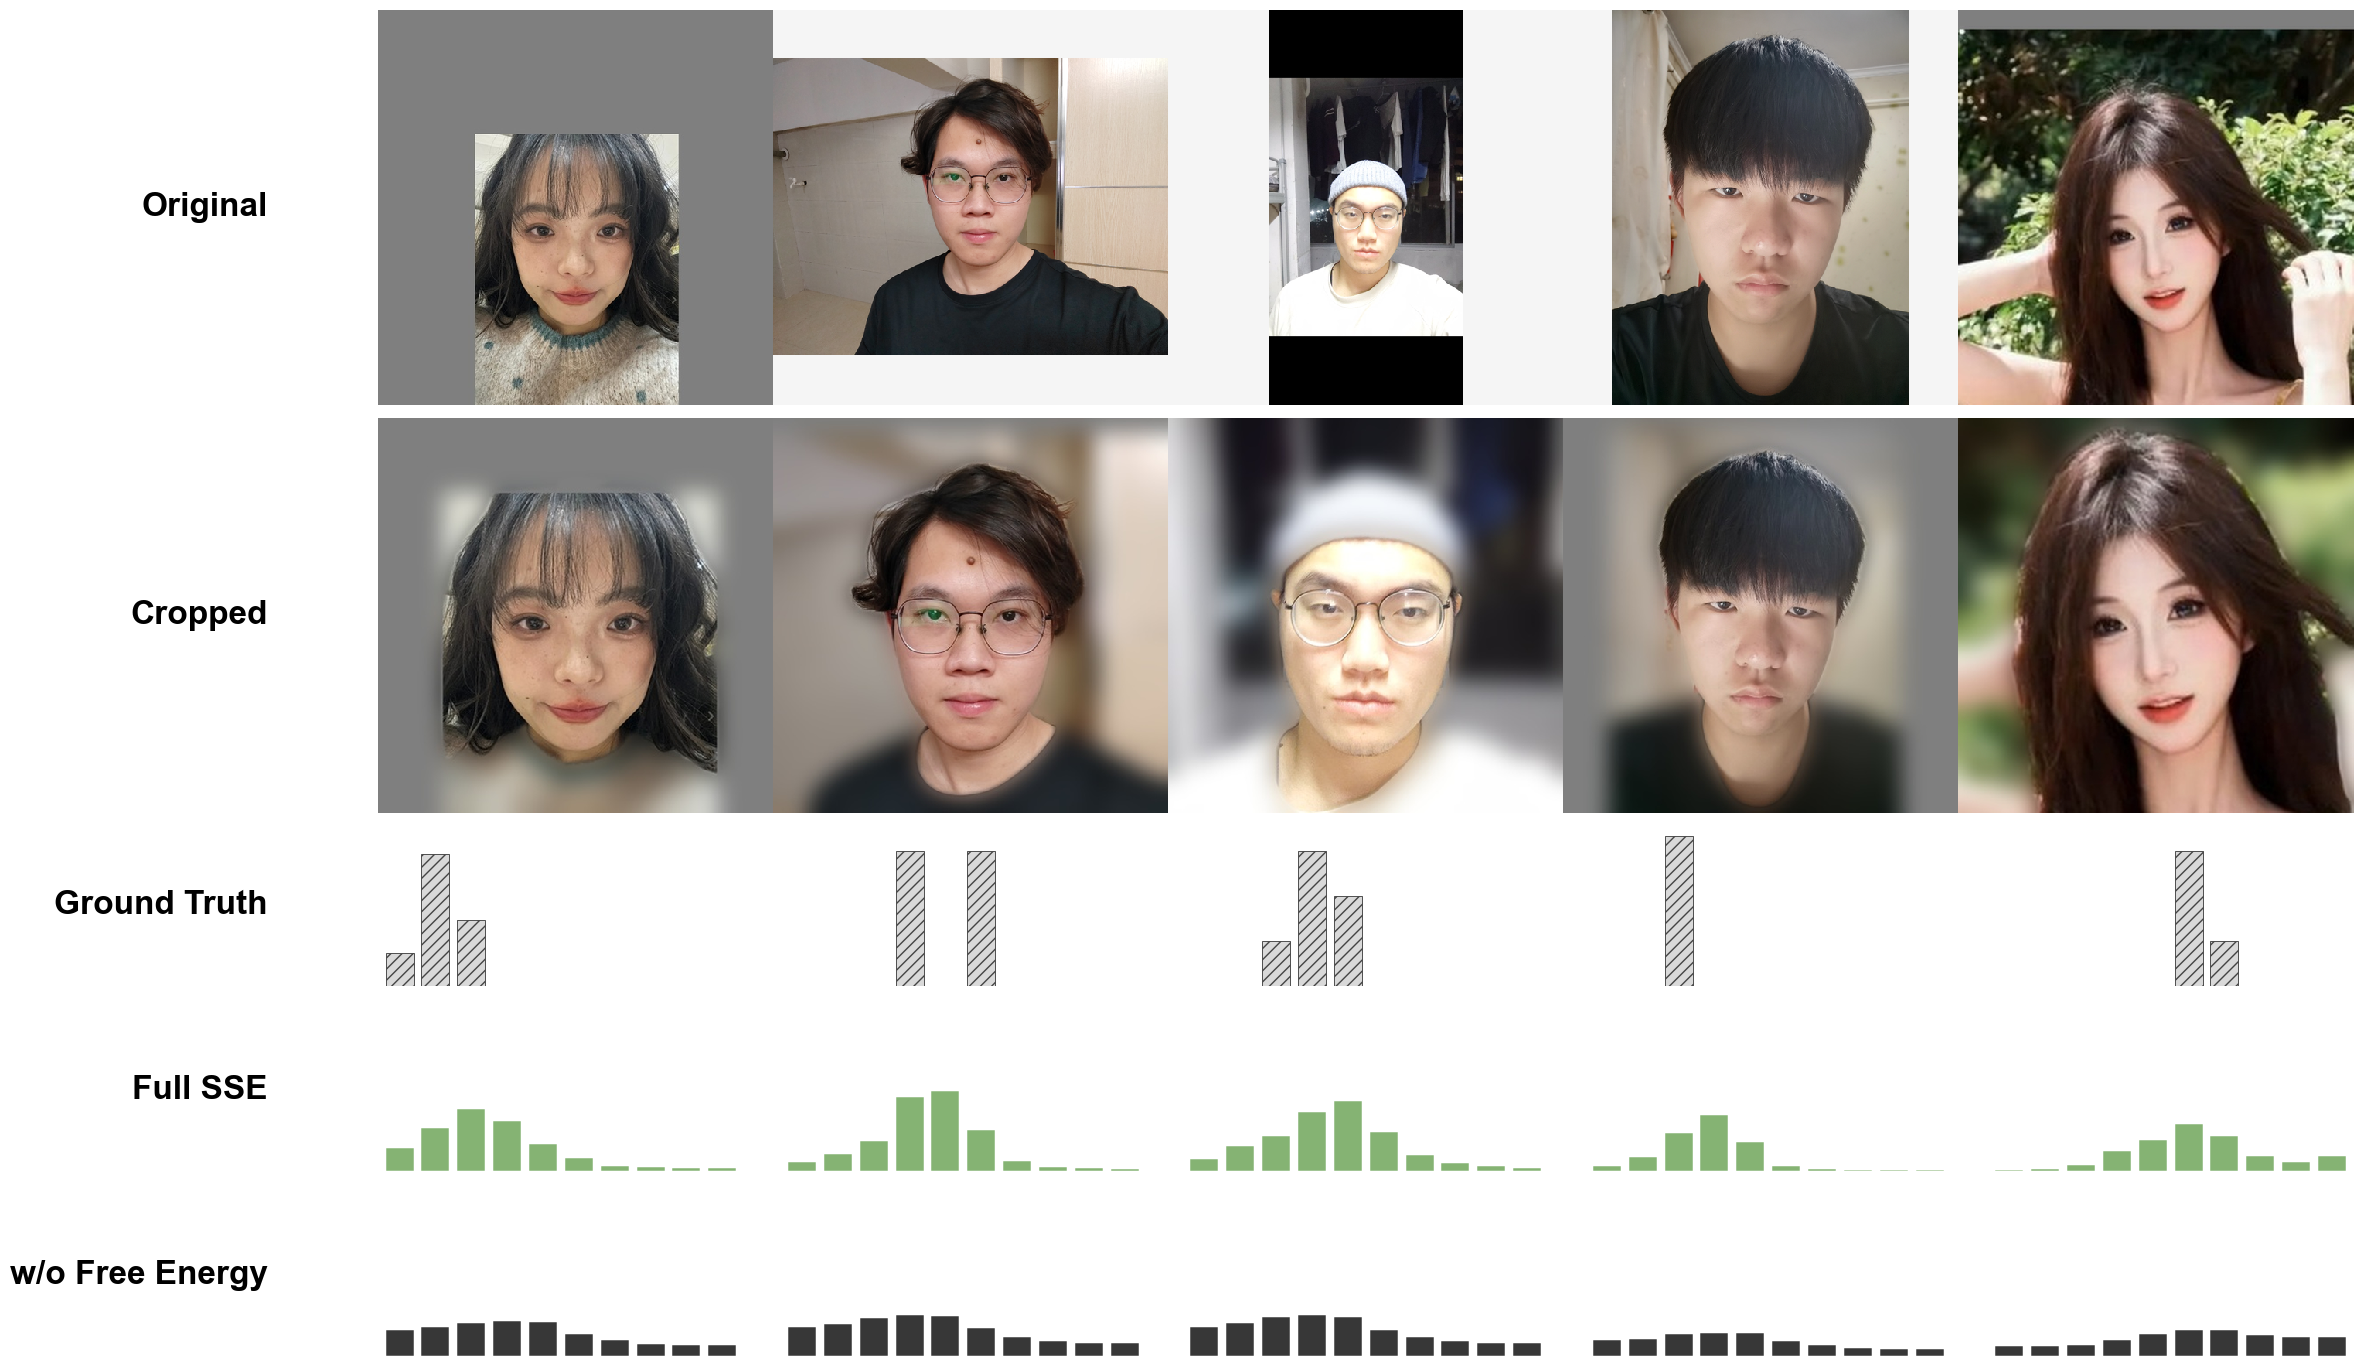

图像已保存到: D:\MyJupyter\Works\FaceScore\outputs\figures\ablation_distribution_comparison.pdf
图片编号: 3822, 3122, 2924, 2964, 3768
模型预测: 5个训练种子的平均概率分布


In [11]:

from pathlib import Path
from PIL import Image,ImageOps
import numpy as np
import matplotlib.pyplot as plt
ROOT_DIR=Path(r'D:\MyJupyter\Works\FaceScore')
RAW_TEST_DIR=ROOT_DIR/'data'/'test_data'
CROPPED_TEST_DIR=ROOT_DIR/'data'/'test_face_data'
FIGURE_DIR=ROOT_DIR/'outputs'/'figures'
IMAGE_IDS=['3822','3122','2924','2964','3768']
PLOT_MODE='mean'
DISPLAY_SEED=42
FIGURE_WIDTH=22
FIGURE_HEIGHT=14
LEFT_MARGIN=0.1
RIGHT_MARGIN=0.998
TOP_MARGIN=0.99
BOTTOM_MARGIN=0.025
IMAGE_WSPACE=0.0
IMAGE_HSPACE=0.01
PLOT_WSPACE=0.1
PLOT_HSPACE=0.15
BLOCK_HSPACE=0.01
IMAGE_BLOCK_RATIO=2.6
PLOT_BLOCK_RATIO=1.7
IMAGE_DISPLAY_SIZE=512
IMAGE_PAD_COLOR='#F5F5F5'
ROW_LABEL_SIZE=24
ROW_LABEL_X_OFFSET=0.05
BAR_WIDTH=0.78
SAVE_DPI=800
SAVE_NAME='ablation_distribution_comparison.pdf'
SAME_Y_SCALE=True
METHODS_TO_PLOT=['full_sse','without_free_energy']
PALETTE=['#85B373','#FF9FA0','#373737','#367FBD','#BD324C','#092DF1','#FC2704']
COLORS={'full_sse':PALETTE[0],'without_free_energy':PALETTE[2]}
DISPLAY_NAMES={'full_sse':'Full SSE','without_free_energy':'w/o Free Energy'}
if len(IMAGE_IDS)!=5 or len({str(item).casefold() for item in IMAGE_IDS})!=5:
    raise ValueError('IMAGE_IDS必须包含5个不同的图片编号')
if PLOT_MODE not in ('mean','seed'):
    raise ValueError("PLOT_MODE必须是'mean'或'seed'")
if PLOT_MODE=='seed' and DISPLAY_SEED not in SEEDS:
    raise ValueError(f'DISPLAY_SEED必须在{SEEDS}中')
if not RAW_TEST_DIR.is_dir() or not CROPPED_TEST_DIR.is_dir():
    raise FileNotFoundError(f'缺少原图或裁剪图目录: {RAW_TEST_DIR} | {CROPPED_TEST_DIR}')
image_paths=[Path(path) for path in test_dataset.image_paths]
if any(path.parent.resolve()!=CROPPED_TEST_DIR.resolve() for path in image_paths):
    raise RuntimeError('当前test_dataset不是从test_face_data加载的，请检查测试集顺序')
if len(image_paths)!=len(test_targets):
    raise RuntimeError('测试图片数量与真实标签数量不一致')
image_lookup={path.stem.casefold():i for i,path in enumerate(image_paths)}
if len(image_lookup)!=len(image_paths):
    raise RuntimeError('裁剪测试集存在相同编号但扩展名不同的照片')
original_paths_list=[path for path in RAW_TEST_DIR.iterdir() if path.suffix.lower() in ('.jpg','.jpeg','.png')]
original_lookup={path.stem.casefold():path for path in original_paths_list}
if len(original_lookup)!=len(original_paths_list):
    raise RuntimeError('原始测试集存在相同编号但扩展名不同的照片')
selected_indices=[]
original_paths=[]
for item in IMAGE_IDS:
    image_id=Path(str(item)).stem.casefold()
    if image_id not in image_lookup:
        raise FileNotFoundError(f'裁剪测试集中没有编号: {item}')
    if image_id not in original_lookup:
        raise FileNotFoundError(f'原始测试集中没有编号: {item}')
    selected_indices.append(image_lookup[image_id])
    original_paths.append(original_lookup[image_id])
predictions_display={}
for method in METHODS_TO_PLOT:
    if method not in all_predictions:
        raise KeyError(f'all_predictions中不存在消融方法: {method}')
    values=np.asarray(all_predictions[method],dtype=np.float64)
    if values.shape!=(len(SEEDS),len(image_paths),10):
        raise RuntimeError(f'{method}的预测结果维度不正确: {values.shape}')
    if not np.isfinite(values).all() or (values<0).any() or not np.allclose(values.sum(axis=2),1.0,atol=1e-5):
        raise RuntimeError(f'{method}包含无效预测概率')
    predictions_display[method]=values.mean(axis=0) if PLOT_MODE=='mean' else values[SEEDS.index(DISPLAY_SEED)]
plt.rcParams['font.family']='Arial'
plt.rcParams['font.sans-serif']=['Arial']
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['pdf.fonttype']=42
plt.rcParams['ps.fonttype']=42
fig=plt.figure(figsize=(FIGURE_WIDTH,FIGURE_HEIGHT))
outer_grid=fig.add_gridspec(2,1,height_ratios=[IMAGE_BLOCK_RATIO,PLOT_BLOCK_RATIO],hspace=BLOCK_HSPACE)
image_grid=outer_grid[0].subgridspec(2,5,wspace=IMAGE_WSPACE,hspace=IMAGE_HSPACE)
plot_grid=outer_grid[1].subgridspec(3,5,wspace=PLOT_WSPACE,hspace=PLOT_HSPACE)
image_axes=[[fig.add_subplot(image_grid[row,col]) for col in range(5)] for row in range(2)]
plot_axes=[[fig.add_subplot(plot_grid[row,col]) for col in range(5)] for row in range(3)]
fig.subplots_adjust(left=LEFT_MARGIN,right=RIGHT_MARGIN,top=TOP_MARGIN,bottom=BOTTOM_MARGIN)
resample=Image.Resampling.LANCZOS if hasattr(Image,'Resampling') else Image.LANCZOS
score_bins=np.arange(1,11,dtype=np.float64)
for col,index in enumerate(selected_indices):
    cropped_path=image_paths[index]
    for image_row,image_path in enumerate((original_paths[col],cropped_path)):
        with Image.open(image_path) as source:
            rgb=ImageOps.exif_transpose(source).convert('RGB')
            display_image=ImageOps.pad(rgb,(IMAGE_DISPLAY_SIZE,IMAGE_DISPLAY_SIZE),method=resample,color=IMAGE_PAD_COLOR)
        ax=image_axes[image_row][col]
        ax.imshow(display_image,interpolation='nearest')
        ax.axis('off')
    target=np.asarray(test_targets[index],dtype=np.float64)
    if target.shape!=(10,) or not np.isfinite(target).all() or (target<0).any() or not np.isclose(target.sum(),1.0,atol=1e-5):
        raise RuntimeError(f'{cropped_path.name}的真实评分分布无效')
    distributions=[target]+[predictions_display[method][index] for method in METHODS_TO_PLOT]
    ymax=min(1.08,max(0.25,np.ceil(max(float(np.max(p)) for p in distributions)*11.0)/10.0))
    for plot_row,distribution in enumerate(distributions):
        ax=plot_axes[plot_row][col]
        is_gt=plot_row==0
        color='#D9D9D9' if is_gt else COLORS[METHODS_TO_PLOT[plot_row-1]]
        ax.bar(score_bins,distribution,width=BAR_WIDTH,color=color,edgecolor='#444444' if is_gt else 'white',linewidth=0.65 if is_gt else 0.35,hatch='///' if is_gt else None,zorder=3)
        ax.set_xlim(0.4,10.6)
        if SAME_Y_SCALE:
            ax.set_ylim(0,ymax)
        else:
            individual_ymax=min(1.08,max(0.15,float(np.max(distribution))*1.15))
            ax.set_ylim(0,individual_ymax)
        ax.axis('off')
row_names=['Original','Cropped','Ground Truth']+[DISPLAY_NAMES[method] for method in METHODS_TO_PLOT]
all_axes=image_axes+plot_axes
for row,row_name in enumerate(row_names):
    position=all_axes[row][0].get_position()
    fig.text(position.x0-ROW_LABEL_X_OFFSET,(position.y0+position.y1)/2,row_name,fontsize=ROW_LABEL_SIZE,fontfamily='Arial',ha='right',va='center',fontweight='bold')
FIGURE_DIR.mkdir(parents=True,exist_ok=True)
figure_path=FIGURE_DIR/SAVE_NAME
fig.savefig(figure_path,dpi=SAVE_DPI,bbox_inches='tight',facecolor='white')
plt.show()
plt.close(fig)
print(f'图像已保存到: {figure_path}')
print('图片编号: '+', '.join(image_paths[i].stem for i in selected_indices))
print('模型预测: 5个训练种子的平均概率分布' if PLOT_MODE=='mean' else f'模型预测: 随机种子{DISPLAY_SEED}')
